![Banner](../images/09_09_banner_rs_image_classification.png)


# Sampling, Accuracy Assessment and Reproducible Runs

A land-cover map is only as trustworthy as its accuracy assessment.


## Overview

This notebook shows how the way you **split** labelled pixels changes the accuracy you report, how to build **feature stacks** from Sentinel-2 and Sentinel-1, how to report accuracy with **uncertainty**, how to turn sample counts into **area-adjusted** estimates, and how to make every run **reproducible**.

**Data (CPU only).** `Sentinel_2_UB` (10 bands, ground-truth polygons) and `Sentinel_01_UB` (VV/VH backscatter and GLCM texture) for an urban scene in UTM zone 17N with 10 m pixels.


## Core concepts

### Learning objectives

1. Use the data model: `load_stack`, `RasterMeta`, `as_band_dataset`/`as_band_array`, `labels_from_table`, `rasterize_labels`, `sample_pixels` and a `Normalizer` fitted on training data only.
2. Compare random, spatial-block, group and spatial k-fold splits and quantify how much each inflates accuracy.
3. Build feature stacks (bands, indices, SAR, texture) and evaluate them with `spatial_cross_validate`.
4. Use the lightweight `classify` API (`Classifier`, `extract_samples`, `cluster`) and know when to prefer it.
5. Report accuracy beyond OA: bootstrap confidence intervals, confusion matrices, user's and producer's accuracy.
6. Compute area-adjusted accuracy and area estimates with `classify.olofsson`.
7. Locate errors with `error_map` and test the model against baselines.
8. Record and replay a run with `RunConfig`, `save_run`/`load_run` and the command line.

### Contents

1. Setup and data model
2. Labels, rasterization and sampling
3. Normalization without leakage
4. Split strategies compared
5. Feature stacks and spatial cross-validation
6. The lightweight `classify` API
7. Accuracy beyond overall accuracy
8. Area-adjusted accuracy (Olofsson)
9. Where the map is wrong, and baselines
10. Reproducibility and the command line


## Setup and data model

`load_stack` reads a GeoTIFF, or a folder of single-band GeoTIFFs, into one `xarray.DataArray` with dims `(band, y, x)`. Nodata becomes NaN and the CRS, transform and provenance travel with the array. Files that are not on the same grid are refused unless you resample them, so a silent misregistration cannot happen.

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# warnings, JSON, shell commands, Python path, temporary folders
import warnings, json, subprocess, sys, tempfile
from pathlib import Path  # file paths
warnings.filterwarnings("ignore")  # hide library warnings

# arrays, tables, vector data and labelled rasters
import numpy as np, pandas as pd, geopandas as gpd, xarray as xr
import matplotlib.pyplot as plt  # figures
from sklearn.ensemble import RandomForestClassifier  # random forest classifier

from geolattice.rsense import classify  # GeoLattice classification helpers (Classifier, accuracy, Olofsson areas)
import geolattice.rsense.classify.image_classification as ic  # GeoLattice image-classification module

DATA = Path("../../../../Data/08_remote_sensing/08_09_image_classification")  # data folder
S2_DIR = DATA / "Sentinel_2_UB" / "Images"  # Sentinel-2 band files of the UB campus
S1_BANDS = DATA / "Sentinel_01_UB" / "Bands"  # Sentinel-1 VV and VH backscatter
S1_TEX = DATA / "Sentinel_01_UB" / "Texture"  # Sentinel-1 texture layers
LABELS = DATA / "Sentinel_2_UB" / "Label_Point_Data"  # labelled points and polygons
CRS = "EPSG:32617"  # UTM zone 17N (the files carry no CRS)
ic.set_seed(42)  # reproducible random numbers in numpy and PyTorch
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})  # figure resolution, no grid lines

In [2]:
s2 = ic.load_stack(S2_DIR, crs=CRS)          # the S2 files carry no CRS, so we supply it
print(s2.dims, s2.shape, list(s2.band.values))  # dimensions, shape and band names
print("nodata -> NaN:", int(np.isnan(s2).sum()), "NaN pixels")  # no-data pixels become NaN
meta = ic.RasterMeta.from_dataarray(s2)  # grid metadata of the stack
meta.to_dict()  # as a dictionary

('band', 'y', 'x') (10, 170, 210) [np.str_('B2'), np.str_('B3'), np.str_('B4'), np.str_('B5'), np.str_('B6'), np.str_('B7'), np.str_('B8'), np.str_('B8A'), np.str_('B11'), np.str_('B12')]
nodata -> NaN: 0 NaN pixels


{'crs': 'PROJCS["WGS 84 / UTM zone 17N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-81],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32617"]]',
 'transform': (10.0, 0.0, 677770.0, 0.0, -10.0, 4764070.0),
 'nodata': -3.3999999521443642e+38,
 'band_names': ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12'],
 'shape': (170, 210),
 'dtype': 'float32',
 'acquisition_dates': [],
 'sensor': None,
 'sources': ['../../../../Data/08_remote_sensing/08_09_image_classification/Sentinel_2_UB/Images/B2.tif',
  '../../../../Data/08

`RasterMeta` is a small record of CRS, transform, shape and band names. It is what `save_run` stores so a map can be georeferenced again later.

Sentinel-1 lives on a larger grid (441 × 285 px) than the Sentinel-2 subset (210 × 170 px) although both have 10 m pixels and the same CRS. `load_stack` would raise on the mismatch; the safe route is to resample explicitly onto the S2 grid.


In [3]:
s1_raw = ic.load_stack(S1_BANDS, pattern="V*.tif", crs=CRS)  # the Sentinel-1 VV and VH files
tex_raw = ic.load_stack(S1_TEX, crs=CRS)  # the Sentinel-1 texture layers
# the Sentinel-1 grid is larger than the Sentinel-2 grid
print("S1 grid  :", s1_raw.shape, "| S2 grid:", s2.shape)
try:
    ic.load_stack([S2_DIR / "B2.tif", S1_BANDS / "VV.tif"], crs=CRS)  # stacking files on different grids ...
except ValueError as e:
    print("refused  :", e)  # ... is refused with a clear error

ref = s2.isel(band=0)  # the Sentinel-2 grid as template
s1 = s1_raw.rio.reproject_match(ref)       # same CRS and 10 m: pure window cut, no resampling
tex = tex_raw.rio.reproject_match(ref)  # textures cut to the same window
# aligned shapes and the share of gaps
print("aligned  :", s1.shape, tex.shape, "NaN share:", float(np.isnan(s1).mean()))

S1 grid  : (2, 285, 441) | S2 grid: (10, 170, 210)
refused  : VV.tif is not on the grid of B2.tif; resample it first or pass align=True (recorded in attrs).
aligned  : (2, 170, 210) (12, 170, 210) NaN share: 0.0


### `as_band_dataset` and `as_band_array`

A `(band, y, x)` array is convenient for models, but a `Dataset` with one variable per band is convenient for indices and for the `classify` API. The two converters are lossless inverses.


In [4]:
ds = ic.as_band_dataset(s2)  # one variable per band
print(list(ds.data_vars)[:4], "...")  # the first few variable names
back = ic.as_band_array(ds)  # and back to a (band, y, x) array
# values and CRS survive the round trip
print("round trip identical:", bool(np.allclose(back.values, s2.values, equal_nan=True)),
      "| CRS kept:", back.rio.crs)

def nd(a, b):  # normalised difference of two bands
    # (a - b) / (a + b), with a tiny term to avoid division by zero
    return (ds[a] - ds[b]) / (ds[a] + ds[b] + 1e-6)

ds["NDVI"], ds["NDWI"] = nd("B8", "B4"), nd("B3", "B8")  # vegetation and water indices
ds["NDBI"], ds["MNDWI"] = nd("B11", "B8"), nd("B3", "B11")  # built-up and modified water indices
s2_idx = ic.as_band_array(ds)  # the bands plus four indices as one stack
print(s2_idx.shape, list(s2_idx.band.values)[-4:])  # shape and the new band names

['B2', 'B3', 'B4', 'B5'] ...
round trip identical: True | CRS kept: EPSG:32617
(14, 170, 210) ['NDVI', 'NDWI', 'NDBI', 'MNDWI']


The indices are normalized differences

$$
\mathrm{NDVI}=\frac{\rho_{\text{NIR}}-\rho_{\text{Red}}}{\rho_{\text{NIR}}+\rho_{\text{Red}}},\quad
\mathrm{NDWI}=\frac{\rho_{G}-\rho_{\text{NIR}}}{\rho_{G}+\rho_{\text{NIR}}},\quad
\mathrm{NDBI}=\frac{\rho_{\text{SWIR1}}-\rho_{\text{NIR}}}{\rho_{\text{SWIR1}}+\rho_{\text{NIR}}},\quad
\mathrm{MNDWI}=\frac{\rho_{G}-\rho_{\text{SWIR1}}}{\rho_{G}+\rho_{\text{SWIR1}}}
$$

with $\rho_{\text{NIR}}=$ B8, $\rho_{\text{Red}}=$ B4, $\rho_G=$ B3 and $\rho_{\text{SWIR1}}=$ B11.


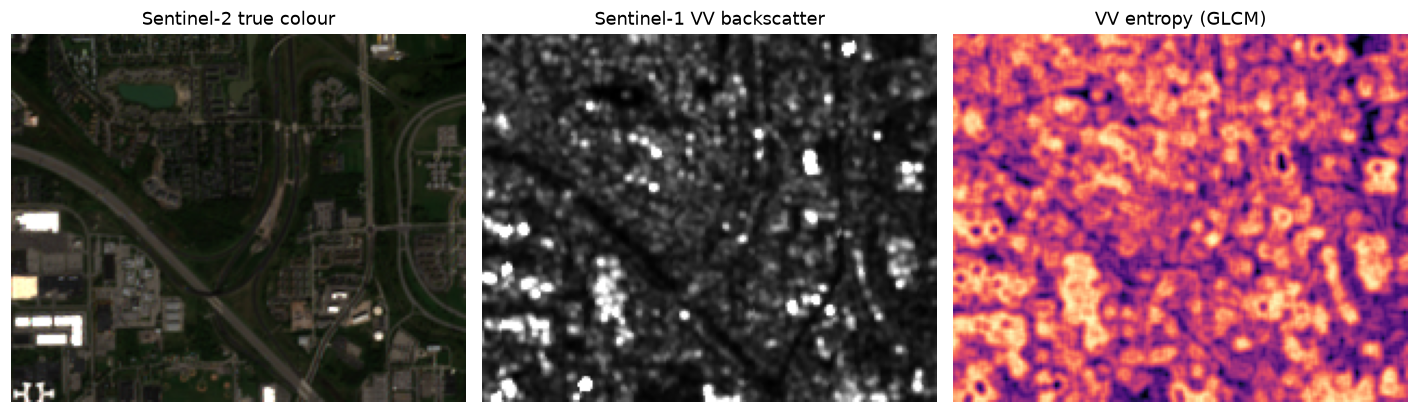

In [5]:
rgb = s2.sel(band=["B4", "B3", "B2"]).values  # red, green, blue
# stretch to the 99th percentile and move bands last
rgb = np.clip(rgb / np.nanpercentile(rgb, 99), 0, 1).transpose(1, 2, 0)
fig, ax = plt.subplots(1, 3, figsize=(13, 4))  # three panels
ax[0].imshow(rgb); ax[0].set_title("Sentinel-2 true colour")  # true colour
# VV backscatter
ax[1].imshow(s1.sel(band="VV").values, cmap="gray", vmax=np.nanpercentile(s1.sel(band="VV"), 98))
ax[1].set_title("Sentinel-1 VV backscatter")  # title
# VV GLCM entropy
ax[2].imshow(tex.sel(band="VV_ENT").values, cmap="magma"); ax[2].set_title("VV entropy (GLCM)")
for a in ax: a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # arrange and draw

## Labels, rasterization and sampling

The ground truth is a set of hand-drawn polygons. Each polygon is a **group**: all its pixels are spectrally and spatially alike, which matters for validation (section 4). Two small clean-ups are needed: a spelling variant in the class name, and an integer code per class.

`labels_from_table` builds point labels from a CSV with `x`/`y` columns. The same folder has one (`point_data.csv`, 23,945 points at 2.5 m spacing, i.e. several points per 10 m pixel). We load it only to show why polygons are the better sampling frame here.


In [6]:
# labelled points as a GeoDataFrame
pts = ic.labels_from_table(LABELS / "point_data.csv", x="x", y="y", label="Class_ID", crs=CRS)
# pixel column and row of every point
xy_pix = pd.DataFrame({"c": ((pts.geometry.x - 677770) // 10).astype(int),
                       "r": ((4764070 - pts.geometry.y) // 10).astype(int)})
# many points share one pixel
print(f"{len(pts):,} points fall in only {len(xy_pix.drop_duplicates()):,} distinct 10 m pixels")
# typical number of points per pixel
print("points per pixel (median):", int(xy_pix.groupby(['c', 'r']).size().median()))

23,945 points fall in only 2,135 distinct 10 m pixels
points per pixel (median): 12


Several points per pixel are *replicates*, not independent samples. If they were split at random between train and test, the same pixel would sit on both sides. Polygons avoid this and give us a polygon ID for group splitting.


In [7]:
poly = gpd.read_file(LABELS / "GroundTruth_data.shp").set_crs(CRS)  # the labelled polygons
# fix a typo in one class name
poly["Class"] = poly["Class"].replace({"Praking/road/pavement": "Parking/road/pavement"})
NAMES = ["Parking/road/pavement", "Building", "Tree/bushes", "Grass", "Water"]  # the five classes in order
poly["cid"] = poly["Class"].map({n: i + 1 for i, n in enumerate(NAMES)})  # class name -> id 1-5
poly["pid"] = np.arange(len(poly))  # a unique id for every polygon
CLASS_NAMES = {i + 1: n for i, n in enumerate(NAMES)}  # id -> name
print(poly.groupby("Class").size().reindex(NAMES).rename("polygons"))  # polygons per class

Class
Parking/road/pavement    30
Building                 42
Tree/bushes              17
Grass                    18
Water                     6
Name: polygons, dtype: int64


codes: {'1': 1, '2': 2, '3': 3, '4': 4, '5': 5} | labelled pixels: 1637


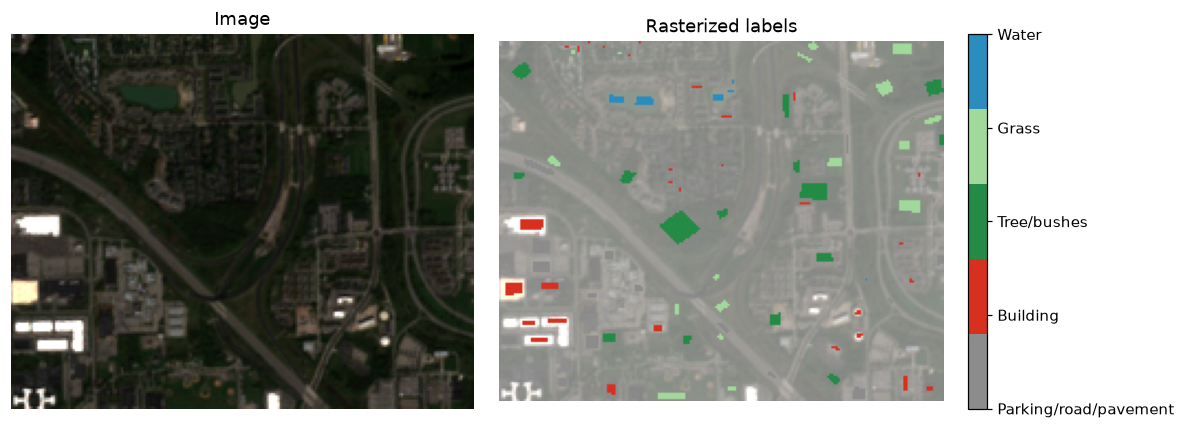

In [8]:
template = s2.isel(band=0)  # the 10 m grid
lab, codes = ic.rasterize_labels(poly, template, "cid")   # label raster, -1 = unlabeled
pidr, _ = ic.rasterize_labels(poly, template, "pid")      # polygon id on the same grid
# class codes and labelled pixel count
print("codes:", codes, "| labelled pixels:", int((lab.values != -1).sum()))
cmap_cls = plt.matplotlib.colors.ListedColormap(["#8c8c8c", "#d7301f", "#238b45", "#a1d99b", "#2b8cbe"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))  # two panels
ax[0].imshow(rgb); ax[0].set_title("Image")  # the image
m = np.ma.masked_equal(lab.values, -1)  # hide unlabelled pixels
ax[1].imshow(rgb, alpha=.5); im = ax[1].imshow(m, cmap=cmap_cls, vmin=1, vmax=5)  # labels over the faded image
ax[1].set_title("Rasterized labels")  # title
# class names on the colour bar
cb = plt.colorbar(im, ax=ax[1], ticks=range(1, 6), fraction=.04); cb.ax.set_yticklabels(NAMES)
for a in ax: a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # arrange and draw

`sample_pixels` turns a label raster (or polygons or points) and an image into `X` (features), `y` (labels) and `coords` (map x, y of each pixel). The coordinates are what the spatial splitters need. Sampling the polygon-ID raster with the same image returns the polygon of every row, in the same order.


In [9]:
def sample(img):  # features, labels, coordinates and polygon id of every labelled pixel
    X, y, coords = ic.sample_pixels(img, lab)  # feature table, class and coordinates
    _, groups, _ = ic.sample_pixels(img, pidr)  # polygon id of the same pixels
    return X, y.astype(int), coords, groups.astype(int)  # as integer arrays

X, y, coords, groups = sample(s2_idx)  # sample the bands plus indices
print("X:", X.shape, "| polygons:", len(np.unique(groups)))  # sample size and number of polygons
print(pd.Series(y).map(CLASS_NAMES).value_counts().rename("pixels"))  # pixels per class

X: (1637, 14) | polygons: 93
Tree/bushes              576
Parking/road/pavement    368
Grass                    342
Building                 275
Water                     76
Name: pixels, dtype: int64


## Normalization without leakage

A scaler has parameters (mean, standard deviation, percentiles) that are estimated from data. If they are estimated on *all* pixels, the test set has influenced the model input. The rule is: **fit on training data only**, then apply the frozen scaler to everything else.

For the z-score, with training mean $\mu_b$ and standard deviation $\sigma_b$ of band $b$,

$$ z_{ib}=\frac{x_{ib}-\mu_b}{\sigma_b}. $$

Min-max and percentile scalers follow the same rule with different parameters.


In [10]:
# 300 m spatial blocks, 30 % of blocks for testing, class-balanced
split = ic.spatial_block_split(coords, block_size=300, test_size=0.3, seed=0, stratify=y)
norm = ic.Normalizer("zscore").fit(X.iloc[split.train])        # training pixels only
# apply the training scaling to both sets
Xtr, Xte = norm.transform(X.iloc[split.train]), norm.transform(X.iloc[split.test])
# training features are centred, test features are not exactly
print("train mean ~0:", np.round(Xtr.mean().mean(), 3), "| test mean (not 0, as it should be):",
      np.round(Xte.mean().mean(), 3))
state = norm.to_dict()  # the scaler as a dictionary
print("serialisable keys:", list(state)[:4])  # its keys
ic.Normalizer.from_dict(state).transform(X.iloc[split.test]).equals(Xte)  # rebuilding it gives the same result

train mean ~0: -0.0 | test mean (not 0, as it should be): 0.219
serialisable keys: ['method', 'low', 'high', 'center']


True

## Split strategies compared

Neighbouring pixels are more alike than distant ones (spatial autocorrelation). A random pixel split puts near-twins on both sides of the split, so the test score measures *memorization of neighbours* rather than generalization to new places. If $\rho(h)$ is the correlation of labels and features at distance $h$, the effective number of independent samples is much smaller than $n$ whenever $\rho(h)>0$ over the sample spacing.

Four strategies:

| Strategy | Unit that is kept whole | Function |
|---|---|---|
| Random pixels | nothing | `train_test_split` |
| Spatial blocks | square blocks of side $s$ | `spatial_blocks`, `spatial_block_split` |
| Group | polygon ID | `group_split` |
| Spatial k-fold | blocks, rotated over $k$ folds | `spatial_kfold` |

`spatial_blocks` shows the blocks; the block side is in map units (metres here).


blocks: 40 | pixels per block (median): 31


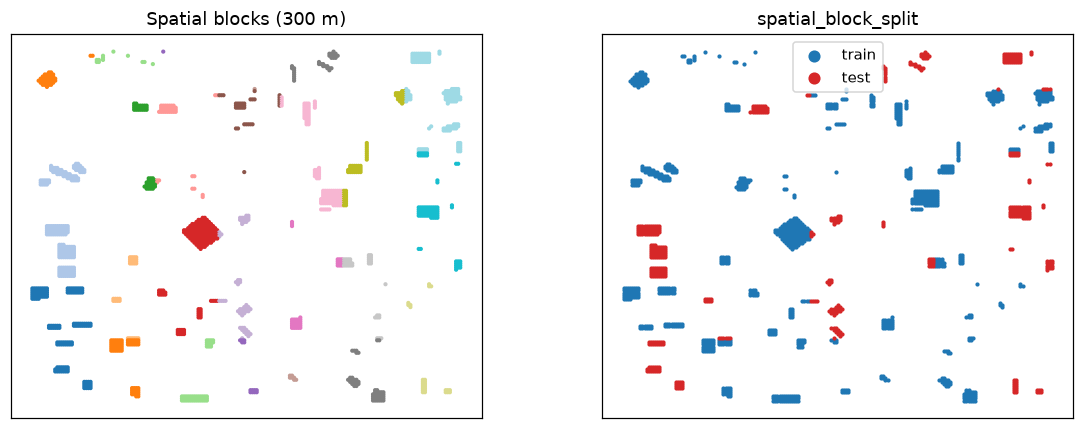

split kind: spatial-block | train/test: 1123 514


In [11]:
BS = 300  # block size in metres
blk = ic.spatial_blocks(coords, block_size=BS)  # block id of every pixel
# number of blocks and pixels per block
print("blocks:", len(np.unique(blk)), "| pixels per block (median):", int(pd.Series(blk).value_counts().median()))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))  # two panels
# pixels coloured by block
ax[0].scatter(coords[:, 0], coords[:, 1], c=blk, s=3, cmap="tab20"); ax[0].set_title(f"Spatial blocks ({BS} m)")
tr, te = split.train, split.test  # training and test pixels
# coloured by split
ax[1].scatter(*coords[tr].T, s=3, c="tab:blue", label="train"); ax[1].scatter(*coords[te].T, s=3, c="tab:red", label="test")
ax[1].legend(markerscale=4); ax[1].set_title("spatial_block_split")  # legend and title
for a in ax: a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])  # equal scale, no ticks
plt.tight_layout(); plt.show()  # arrange and draw
# no pixel in both sets
split.check(); print("split kind:", split.kind, "| train/test:", len(split.train), len(split.test))

In [12]:
def rf(): return RandomForestClassifier(300, random_state=0, n_jobs=-1)  # a fresh random forest

def score(tr, te, Xm=X):  # test accuracy of a random forest for one split
    # fit on the training rows, predict the test rows
    m = rf().fit(Xm.iloc[tr], y[tr]); p = m.predict(Xm.iloc[te])
    return float((p == y[te]).mean())  # share of correct predictions

rng = np.random.default_rng(0)  # random generator
perm = rng.permutation(len(y)); k = int(0.7 * len(y))  # random 70/30 pixel split
# random pixels versus spatial blocks
res = {"random pixels": score(perm[:k], perm[k:]), "spatial blocks": score(split.train, split.test)}
gsplit = ic.group_split(groups, test_size=0.3, seed=0)  # whole polygons in train or test
res["group (polygon)"] = score(gsplit.train, gsplit.test)  # its accuracy
# 5-fold spatial cross-validation
folds = [score(a, b) for a, b in ic.spatial_kfold(coords, block_size=BS, n_splits=5, seed=0)]
res["spatial 5-fold (mean)"] = float(np.mean(folds))  # mean of the folds
out = pd.Series(res, name="OA").to_frame()  # as a table
# how much each split overstates the spatial estimate
out["inflation vs spatial blocks"] = out["OA"] - out.loc["spatial blocks", "OA"]
out.round(3)  # show it

,OA,inflation vs spatial blocks
random pixels,0.963,0.102
spatial blocks,0.862,0.000
group (polygon),0.843,-0.018
spatial 5-fold (mean),0.876,0.014


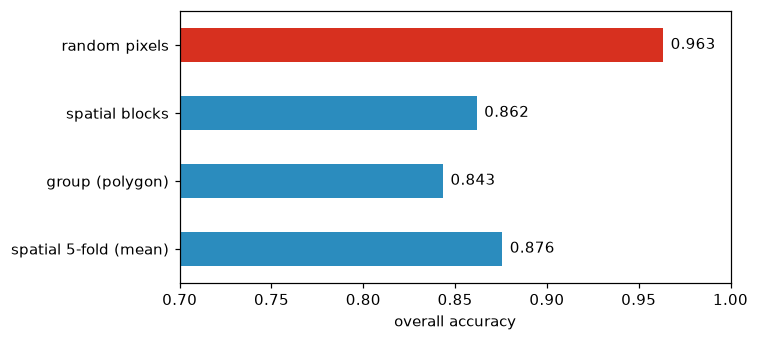

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.2))  # one panel
out["OA"].plot.barh(ax=ax, color=["#d7301f", "#2b8cbe", "#2b8cbe", "#2b8cbe"])
# axis range and label, first bar on top
ax.set_xlim(0.7, 1); ax.set_xlabel("overall accuracy"); ax.invert_yaxis()
for i, v in enumerate(out["OA"]): ax.text(v + .004, i, f"{v:.3f}", va="center")  # values next to the bars
plt.tight_layout(); plt.show()  # arrange and draw

Random splitting reports the highest accuracy; the honest strategies agree with each other at a markedly lower value. The gap is the **optimism** of the random split. Which honest strategy to use depends on how the map will be used:

* **Group split** when the question is "does the model work on unseen *objects* (polygons)?".
* **Spatial blocks/k-fold** when the question is "does it work in unseen *places*?" and polygons are not available or are large.

A guard against accidents is `check_split_isolation`, which raises if two id sets overlap:


In [14]:
# the polygon split shares no polygon
print(ic.check_split_isolation(train=groups[gsplit.train], test=groups[gsplit.test]))
try:
    ic.check_split_isolation(train=groups[perm[:k]], test=groups[perm[k:]])  # the random split does
except ValueError as e:
    print("random split:", e)  # print the overlap

True
random split: splits 'train' and 'test' share 73 ids


## Feature stacks and spatial cross-validation

More features do not always help, and the only fair way to tell is spatial cross-validation. For $k$ folds with test blocks $B_1,\dots,B_k$,

$$ \widehat{\mathrm{OA}}_{cv}=\frac1k\sum_{f=1}^{k}\mathrm{OA}_f,\qquad \mathrm{OA}_f=\frac{1}{|B_f|}\sum_{i\in B_f}\mathbb 1[\hat y_i=y_i], $$

with each model trained on the other blocks. `spatial_cross_validate` returns one row per fold.

Stacks compared: (a) Sentinel-2 bands, (b) + spectral indices, (c) + Sentinel-1 VV/VH backscatter, (d) + 12 GLCM texture layers.


In [15]:
stacks = {  # four nested feature stacks
    "S2 bands": s2,
    "S2 + indices": s2_idx,
    "+ S1 VV/VH": xr.concat([s2_idx, s1], dim="band"),
    "+ S1 texture": xr.concat([s2_idx, s1, tex], dim="band"),
}
rows, cv_tables = [], {}  # scores and fold tables
for name, img in stacks.items():  # each stack
    Xk, _, _ = ic.sample_pixels(img, lab)  # its features at the labelled pixels
    # 5-fold spatial cross-validation
    cv = ic.spatial_cross_validate(rf, Xk, y, coords, block_size=BS, n_splits=5, seed=0)
    cv_tables[name] = cv  # keep the fold table
    # mean and spread of the fold scores
    rows.append({"stack": name, "features": Xk.shape[1], "OA": cv.accuracy.mean(), "OA sd": cv.accuracy.std(),
                 "macro-F1": cv.macro_f1.mean(), "kappa": cv.kappa.mean()})
stack_table = pd.DataFrame(rows).set_index("stack")  # as a table
stack_table.round(3)  # show it

,features,OA,OA sd,macro-F1,kappa
stack,,,,,
S2 bands,10,0.880,0.016,0.831,0.822
S2 + indices,14,0.876,0.011,0.817,0.814
+ S1 VV/VH,16,0.891,0.044,0.838,0.839
+ S1 texture,28,0.894,0.043,0.846,0.846


   fold  n_train  n_test  accuracy  macro_f1  kappa
0     0     1227     410     0.893     0.894  0.849
1     1     1341     296     0.919     0.858  0.883
2     2     1337     300     0.923     0.896  0.900
3     3     1302     335     0.916     0.759  0.825
4     4     1341     296     0.821     0.824  0.770


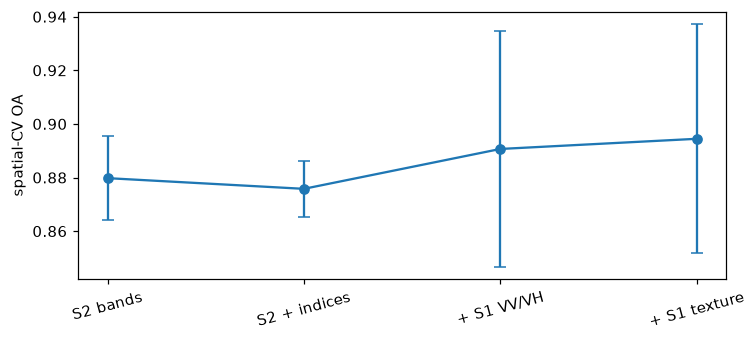

In [16]:
print(cv_tables["+ S1 texture"].round(3))  # the folds of the richest stack
fig, ax = plt.subplots(figsize=(7, 3.2))  # one panel
# mean accuracy with its spread
ax.errorbar(range(len(stack_table)), stack_table["OA"], yerr=stack_table["OA sd"], fmt="o-", capsize=4)
ax.set_xticks(range(len(stack_table))); ax.set_xticklabels(stack_table.index, rotation=15)  # stack names
ax.set_ylabel("spatial-CV OA"); plt.tight_layout(); plt.show()  # label and draw

Optical indices add nothing here because they are functions of bands the forest already sees (OA even dips slightly). The radar layers bring *new* information (structure, moisture, roughness) and lift OA, macro-F1 and kappa by about one point each, and texture adds a little more. The fold-to-fold spread (`OA sd`, up to 0.04 once radar is added) is as large as these gains, so treat them as suggestive rather than proven; this is what the confidence intervals in section 7 are for.


## The lightweight `classify` API

`classify` works on `xarray` Datasets and needs no explicit sampling or splitting code:

* `extract_samples(obj, samples, label_col, max_per_polygon=...)` → features at points or inside polygons, with coordinates kept in `X.attrs["coords"]`.
* `Classifier(model)` → one scikit-learn-style estimator (`rf`, `svm`, `xgb`, `knn`, `logistic`, `gbm`, `mlp`) with CPU/GPU auto-selection and `predict_raster`.
* `cluster(obj, n_clusters)` → k-means map with no labels.

Use it for quick mapping, exploration and when you are happy to manage splitting yourself. Use `ic.train_pixel_classifier` (which wraps `Classifier`) when you want leakage-safe spatial cross-validation done for you and a CV table returned. Use the `ic` splitters and `Normalizer` directly when you need control or a record of the split.


In [17]:
full = xr.concat([s2_idx, s1, tex], dim="band")  # every layer in one stack
full_ds = ic.as_band_dataset(full)  # as a Dataset of bands

# at most 60 random pixels from each polygon
Xe, ye = classify.extract_samples(full_ds, poly, "cid", max_per_polygon=60, seed=0)
# sample size, coordinates and polygons kept
print("extracted:", Xe.shape, "| coords kept:", Xe.attrs["coords"].shape, "| polygons kept:", len(np.unique(Xe.attrs["groups"])))

# random forest through the Classifier wrapper
clf_light = classify.Classifier("rf", n_estimators=300, random_state=0).fit(Xe, ye)
print(clf_light)  # its settings
print(clf_light.feature_importance().head(6).round(3))  # the six most important features
quick_map = clf_light.predict_raster(full_ds)  # classify every pixel
print(type(quick_map).__name__, quick_map.dims)  # the result type

extracted: (1499, 28) | coords kept: (1499, 2) | polygons kept: 93


Classifier('rf', task='classification', engine='cpu')
NDWI     0.096
NDVI     0.092
MNDWI    0.089
B11      0.079
B2       0.074
B3       0.065
dtype: float64


DataArray ('y', 'x')


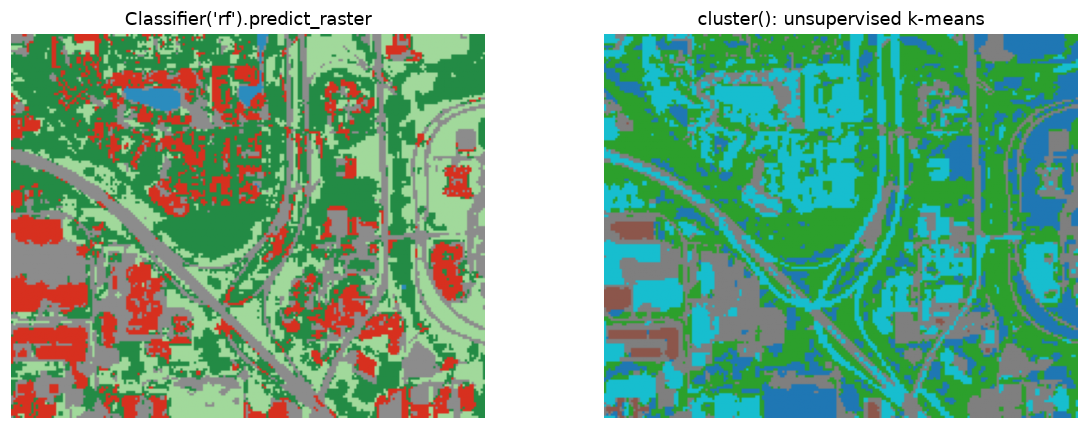

In [18]:
clusters = classify.cluster(full_ds, n_clusters=5, seed=0)  # unsupervised k-means on the same stack
fig, ax = plt.subplots(1, 2, figsize=(11, 4))  # two panels
# the supervised map
ax[0].imshow(quick_map.to_array().squeeze().values if hasattr(quick_map, "to_array") else quick_map.values, cmap=cmap_cls, vmin=1, vmax=5)
ax[0].set_title("Classifier('rf').predict_raster")  # title
# the cluster map
ax[1].imshow(clusters.values, cmap="tab10"); ax[1].set_title("cluster(): unsupervised k-means")
for a in ax: a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # arrange and draw

The supervised map reproduces the polygons' classes; the clusters are unnamed spectral groups that must be matched to classes afterwards. Note that the lightweight route above extracts samples *without* a held-out set: its number on the training pixels would be optimistic. For an honest score, continue with the explicit split below.

The explicit route with `train_pixel_classifier`:


In [19]:
Xf, _, _, _ = sample(full)  # the full feature table
# spatial split with 300 m blocks
sp = ic.spatial_block_split(coords, block_size=BS, test_size=0.3, seed=0, stratify=y)
# random forest with spatial cross-validation on the training blocks
clf, cv = ic.train_pixel_classifier(Xf.iloc[sp.train], y[sp.train], model="rf",
                                    coords=coords[sp.train], block_size=BS, seed=0)
print(type(clf).__name__, "| CV on the training blocks only:")  # model type
print(cv.round(3))  # fold scores
pred = clf.predict(Xf.iloc[sp.test])  # predict the held-out blocks
print("held-out OA:", round(float((pred == y[sp.test]).mean()), 3))  # held-out accuracy

Classifier | CV on the training blocks only:
   fold  n_train  n_test  accuracy  macro_f1  kappa
0     0      695     428     0.963     0.919  0.886
1     1      936     187     0.781     0.808  0.705
2     2      893     230     0.883     0.756  0.826
3     3     1067      56     0.821     0.652  0.733
4     4      901     222     0.851     0.821  0.802
held-out OA: 0.895


## Accuracy beyond overall accuracy

Let $n_{ij}$ be the number of test samples with map class $i$ and reference class $j$, $n=\sum n_{ij}$, $n_{i+}$ and $n_{+j}$ the row and column totals. Then

$$
\mathrm{OA}=\frac{1}{n}\sum_i n_{ii},\qquad
\mathrm{UA}_i=\frac{n_{ii}}{n_{i+}},\qquad
\mathrm{PA}_j=\frac{n_{jj}}{n_{+j}},\qquad
F_1=\frac{2\,\mathrm{UA}\,\mathrm{PA}}{\mathrm{UA}+\mathrm{PA}},
$$

$$
\kappa=\frac{\mathrm{OA}-p_e}{1-p_e},\qquad p_e=\frac{1}{n^2}\sum_i n_{i+}n_{+i}.
$$

User's accuracy (precision) says how reliable a mapped class is; producer's accuracy (recall) says how much of the real class was found. OA alone hides both, especially for rare classes.

**Bootstrap confidence intervals.** Draw $B$ resamples of the test pairs with replacement, recompute each metric $\theta^{*}_b$, and report the $\alpha/2$ and $1-\alpha/2$ percentiles:

$$ \mathrm{CI}_{1-\alpha}(\theta)=\big[\theta^{*}_{(\alpha/2)},\ \theta^{*}_{(1-\alpha/2)}\big]. $$

`classification_report(..., n_boot=...)` does this for OA, kappa, macro-F1 and the per-class F1.


In [20]:
# accuracy report with 500 bootstrap repeats
rep = ic.classification_report(y[sp.test], pred, n_boot=500, seed=0, class_names=CLASS_NAMES)
# sample size and overall scores
print(f"n = {rep['n']}  OA = {rep['overall_accuracy']:.3f}  kappa = {rep['kappa']:.3f}  macro-F1 = {rep['macro_f1']:.3f}")
pd.DataFrame(rep["ci"], index=["2.5 %", "97.5 %"]).T.round(3)  # 95 % confidence intervals

n = 514  OA = 0.895  kappa = 0.857  macro-F1 = 0.898


,2.5 %,97.5 %
oa,0.868,0.918
kappa,0.818,0.889
macro_f1,0.867,0.923


In [21]:
rep["per_class"].round(3)  # per-class precision, recall and F1

,precision,recall,f1,support,f1_ci_low,f1_ci_high
Parking/road/pavement,0.897,0.858,0.877,183,0.841,0.910
Building,0.736,0.844,0.786,96,0.718,0.845
Tree/bushes,0.875,0.833,0.854,42,0.756,0.921
Grass,0.987,0.963,0.975,161,0.959,0.990
Water,1.000,1.000,1.000,32,1.000,1.000


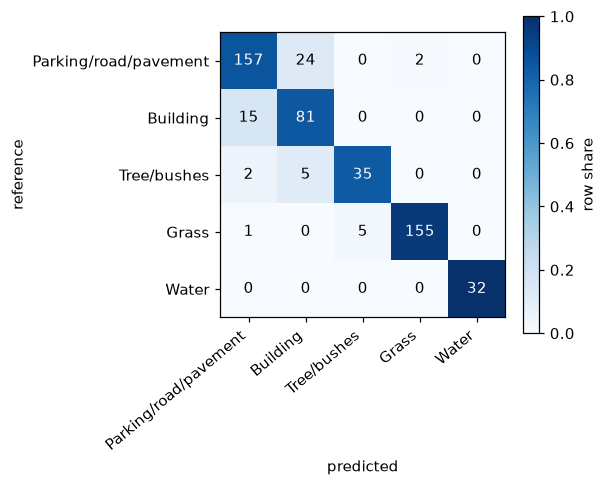

In [22]:
cm = rep["confusion_matrix"]            # reference x predicted
fig, ax = plt.subplots(figsize=(5.5, 4.6))  # one panel
# row shares (producer's view)
im = ax.imshow(cm.values / cm.values.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(5)); ax.set_xticklabels(cm.columns, rotation=40, ha="right")  # predicted classes on x
ax.set_yticks(range(5)); ax.set_yticklabels(cm.index)  # reference classes on y
for i in range(5):  # every cell ...
    for j in range(5):  # ...
        ax.text(j, i, int(cm.values[i, j]), ha="center", va="center",  # its count, in white on dark cells
                color="white" if cm.values[i, j] / cm.values[i].sum() > .5 else "black")
# axis labels and colour bar
ax.set_xlabel("predicted"); ax.set_ylabel("reference"); plt.colorbar(im, label="row share")
plt.tight_layout(); plt.show()  # arrange and draw

`classify.confusion_matrix` uses the opposite orientation, **rows = map**, **columns = reference**, which is the convention of Olofsson et al. (2014) and the one the area estimators need. `classify.accuracy_report` returns OA, kappa and per-class UA/PA/F1 from it. Mind the orientation when comparing with `classification_report` above.


In [23]:
# confusion matrix in the map-accuracy layout
cm_map = classify.confusion_matrix(y[sp.test], pred, labels=[1, 2, 3, 4, 5])
print(cm_map)  # show it
# user's and producer's accuracy per class
ar = classify.accuracy_report(y[sp.test], pred, labels=[1, 2, 3, 4, 5])
ar["per_class"].rename(index=CLASS_NAMES).round(3)  # with class names

reference    1   2   3    4   5
map                            
1          157  15   2    1   0
2           24  81   5    0   0
3            0   0  35    5   0
4            2   0   0  155   0
5            0   0   0    0  32


,users_accuracy,producers_accuracy,f1,n_reference
map,,,,
Parking/road/pavement,0.897,0.858,0.877,183
Building,0.736,0.844,0.786,96
Tree/bushes,0.875,0.833,0.854,42
Grass,0.987,0.963,0.975,161
Water,1.000,1.000,1.000,32


## Area-adjusted accuracy and area estimates (Olofsson)

Counting mapped pixels gives the **mapped** area $A_i$ of class $i$, but a classifier misallocates: commission errors inflate a class and omission errors deflate it. Counting pixels is therefore a **biased** area estimator unless errors exactly cancel. Olofsson et al. (2014) use the reference labels of a probability sample, stratified by map class, to correct this.

With total area $A=\sum_i A_i$ and map-class weights $W_i=A_i/A$, the estimated area proportion in cell $(i,j)$ is

$$ \hat p_{ij}=W_i\,\frac{n_{ij}}{n_{i+}}. $$

Then

$$
\hat p_{+j}=\sum_i \hat p_{ij},\qquad \hat A_j=A\,\hat p_{+j},\qquad
\widehat{\mathrm{OA}}=\sum_j \hat p_{jj},
$$

$$
\widehat{\mathrm{UA}}_i=\frac{\hat p_{ii}}{\hat p_{i+}},\qquad
\widehat{\mathrm{PA}}_j=\frac{\hat p_{jj}}{\hat p_{+j}},
$$

with standard errors

$$
\mathrm{SE}(\hat p_{+j})=\sqrt{\sum_i W_i^{2}\,\frac{\frac{n_{ij}}{n_{i+}}\big(1-\frac{n_{ij}}{n_{i+}}\big)}{n_{i+}-1}},\qquad
\text{CI}_{95\%}(\hat A_j)=\hat A_j\pm 1.96\,A\,\mathrm{SE}(\hat p_{+j}).
$$

`classify.olofsson(cm, map_area, pixel_area=...)` takes the map-by-reference confusion matrix and the mapped pixel counts per class.

**Caveat for this tutorial.** The estimators assume the reference sample is a probability sample stratified by map class. Our reference pixels come from hand-drawn polygons, which are *not* a random sample of the scene, so the output below demonstrates the mechanics and the size of the correction; it is not a publishable area estimate. For a real project, draw a stratified random sample (e.g. 50 to 100 points per class) from the map and label it independently.


In [24]:
cmap = ic.predict_map(clf, full)                         # integer map on the S2 grid
vals, counts = np.unique(cmap.values[cmap.values > 0], return_counts=True)  # mapped pixels per class
map_px = dict(zip(vals.tolist(), counts.tolist()))  # class -> pixel count
ol = classify.olofsson(cm_map, map_px, pixel_area=100.0)  # 100 m2 per 10 m pixel
# area-adjusted accuracy with its interval
print(f"area-adjusted OA = {ol['overall_accuracy']:.3f} +/- {ol['oa_ci']:.3f}   (unadjusted test OA = {rep['overall_accuracy']:.3f})")
tab = ol["table"].rename(index=CLASS_NAMES)  # the area table with class names
tab["map_ha"] = tab["map_area"] / 1e4  # mapped area in hectares
tab["adjusted_ha"] = tab["adjusted_area"] / 1e4  # error-adjusted area
tab["ci_ha"] = tab["area_ci"] / 1e4  # its 95 % interval
tab["adjustment_%"] = 100 * (tab["adjusted_area"] / tab["map_area"] - 1)  # adjustment in percent
# the main columns
tab[["map_ha", "adjusted_ha", "ci_ha", "adjustment_%", "users_accuracy", "ua_ci", "producers_accuracy", "pa_ci"]].round(3)

area-adjusted OA = 0.875 +/- 0.044   (unadjusted test OA = 0.895)


,map_ha,adjusted_ha,ci_ha,adjustment_%,users_accuracy,ua_ci,producers_accuracy,pa_ci
Parking/road/pavement,83.67,90.889,6.631,8.629,0.897,0.045,0.826,0.050
Building,68.72,57.775,6.665,-15.927,0.736,0.083,0.876,0.054
Tree/bushes,136.32,123.360,14.463,-9.507,0.875,0.104,0.967,0.024
Grass,65.32,82.006,14.227,25.545,0.987,0.018,0.786,0.136
Water,2.97,2.970,0.000,-0.000,1.000,0.000,1.000,0.000


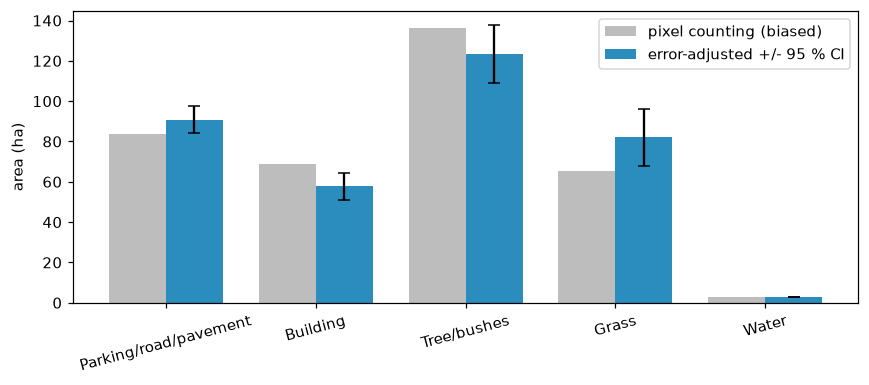

In [25]:
fig, ax = plt.subplots(figsize=(8, 3.6))  # one panel
x = np.arange(len(tab)); w = .38  # bar positions and width
ax.bar(x - w/2, tab["map_ha"], w, label="pixel counting (biased)", color="#bdbdbd")
ax.bar(x + w/2, tab["adjusted_ha"], w, yerr=tab["ci_ha"], capsize=4, label="error-adjusted +/- 95 % CI", color="#2b8cbe")
# class names, label and legend
ax.set_xticks(x); ax.set_xticklabels(tab.index, rotation=15); ax.set_ylabel("area (ha)"); ax.legend()
plt.tight_layout(); plt.show()  # arrange and draw

Classes with low user's accuracy (here Building, which absorbs pavement pixels) are *over*-estimated by counting, and their omissions flow to other classes. The interval on the adjusted area tells you how much of that correction you can trust: wide intervals mean too few reference samples in the confusing classes.


## Where the map is wrong, and baselines

A single accuracy number says nothing about *where* the errors are. `error_map(predicted, reference)` returns 1 where the map agrees with the reference, 0 where it disagrees and NaN where there is no reference. Clusters of errors point to label mistakes, boundary pixels (mixed pixels, misregistration) or domain shift; salt-and-pepper errors point to noise.

Because errors on training pixels are optimistic, we mask the training pixels so the map shows only held-out pixels.


held-out pixels: 514 | agreement: 0.895


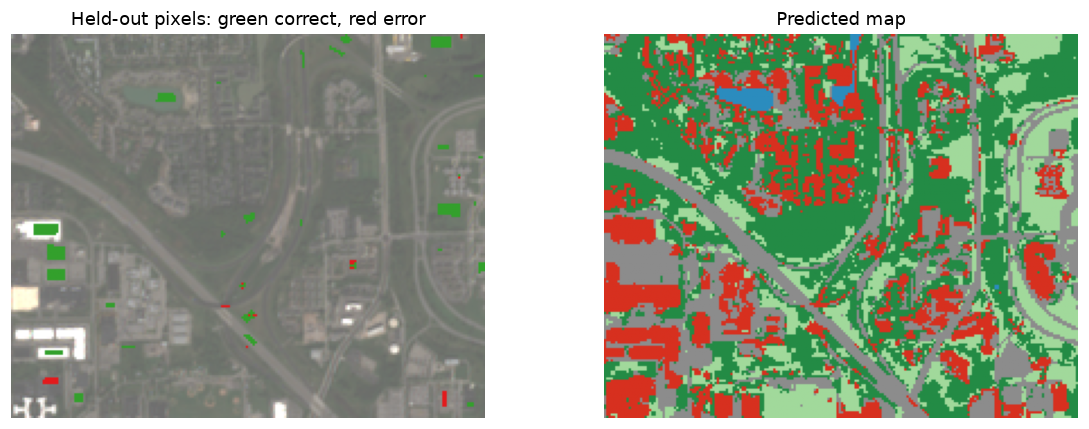

In [26]:
test_lab = np.full(lab.shape, -1, dtype=lab.dtype)  # an empty label raster
r_idx = np.nonzero(lab.values != -1)  # rows and columns of all labelled pixels
# x and y of every column and row
col_of = np.asarray(template.x.values); row_of = np.asarray(template.y.values)
# column and row of each held-out pixel
xs = np.searchsorted(col_of, coords[sp.test, 0]); ys = np.abs(row_of[:, None] - coords[sp.test, 1]).argmin(0)
test_lab[ys, xs] = y[sp.test]  # write their reference classes
test_ref = lab.copy(data=test_lab)  # as a georeferenced raster
err = ic.error_map(cmap, test_ref)  # 1 = correct, 0 = wrong, NaN = not tested
# tested pixels and agreement
print("held-out pixels:", int(np.isfinite(err.values).sum()), "| agreement:", round(float(np.nanmean(err.values)), 3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))  # two panels
ax[0].imshow(rgb, alpha=.6)  # faded image
ax[0].imshow(np.ma.masked_invalid(err.values), cmap=plt.matplotlib.colors.ListedColormap(["#e31a1c", "#33a02c"]), vmin=0, vmax=1)
ax[0].set_title("Held-out pixels: green correct, red error")  # title
ax[1].imshow(cmap.values, cmap=cmap_cls, vmin=1, vmax=5); ax[1].set_title("Predicted map")  # the predicted map
for a in ax: a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # arrange and draw

### Baselines

An accuracy of 0.85 is meaningless without a reference point. `compare_with_baselines` scores a *majority-class* predictor and a *stratified-random* predictor on the same test set next to your models, so you can see how much skill the model really adds. Kappa corrects for chance agreement, so it is the most telling column for the baselines.


In [27]:
nz = ic.Normalizer("zscore").fit(Xf.iloc[sp.train])  # z-score scaling from the training pixels
# logistic regression on scaled features
logit = classify.Classifier("logistic", max_iter=1000).fit(nz.transform(Xf.iloc[sp.train]), y[sp.train])
# support vector machine on scaled features
svm = classify.Classifier("svm").fit(nz.transform(Xf.iloc[sp.train]), y[sp.train])
preds = {"random_forest": pred,  # predictions of the three models
         "logistic (z-score)": logit.predict(nz.transform(Xf.iloc[sp.test])),
         "svm (z-score)": svm.predict(nz.transform(Xf.iloc[sp.test]))}
# against majority-class and stratified-random baselines
base = ic.compare_with_baselines(y[sp.train], y[sp.test], preds, seed=0)
base.round(3)  # show them

,overall_accuracy,kappa,macro_f1
model,,,
majority_baseline,0.082,0.000,0.151
stratified_random_baseline,0.196,0.023,0.179
random_forest,0.895,0.857,0.898
logistic (z-score),0.872,0.827,0.866
svm (z-score),0.875,0.832,0.864


## Reproducibility and the command line

A result is reproducible when someone else (or you in six months) can regenerate it. That needs the **settings**, the **software versions**, the **scaler**, the **class names**, the **georeferencing**, the **exact split** and the **metrics**. `RunConfig` holds the settings; `save_run` writes everything to one JSON file; `load_run` restores it (the `Normalizer` comes back as an object).

`RunConfig` fields `task`, `learning_mode` and `spatial_unit` are validated, so an unsupported combination fails at construction time rather than half-way through a run.


In [28]:
# the run configuration, validated on creation
cfg = ic.RunConfig(task="classification", learning_mode="supervised", spatial_unit="pixel",
                   bands=tuple(full.band.values), seed=42, model="rf", block_size=BS, test_size=0.3,
                   labels=str(LABELS / "GroundTruth_data.shp"), label_col="cid")
try:
    ic.RunConfig(task="not-a-task")  # an unknown task ...
except ValueError as e:
    print("validated:", e)  # ... is rejected

RUN_DIR = Path(tempfile.mkdtemp(prefix="geolattice_run_"))  # a fresh run folder
# save config, scaler, classes, grid, split and scores
path = ic.save_run(RUN_DIR / "run.json", config=cfg, normalizer=nz, class_names=CLASS_NAMES,
                   raster_meta=ic.RasterMeta.from_dataarray(full), split=sp,
                   metrics={k: rep[k] for k in ("overall_accuracy", "kappa", "macro_f1", "n")} | {"ci": rep["ci"]})
print("saved", path.name, f"({path.stat().st_size/1e3:.0f} KB)")  # file name and size

validated: task must be one of ('classification', 'semantic-segmentation', 'detection', 'instance-segmentation', 'change-detection', 'time-series'), got 'not-a-task'


saved run.json (24 KB)


In [29]:
rec = ic.load_run(path)  # load the run back
print("keys           :", list(rec))  # what it contains
print("config.model   :", rec["config"]["model"], "| seed:", rec["config"]["seed"])  # model and seed
print("versions       :", {k: v for k, v in list(rec["versions"].items())[:5]})  # package versions
print("normalizer     :", type(rec["normalizer"]).__name__)  # the restored scaler
# split kind and sizes
print("split          :", rec["split"]["kind"], "| train/test ids:", len(rec["split"]["train"]), len(rec["split"]["test"]))
print("metrics OA     :", round(rec["metrics"]["overall_accuracy"], 3))  # the stored accuracy
Xt = Xf.iloc[sp.test]  # held-out features
# the restored scaler gives the same values
same = np.allclose(rec["normalizer"].transform(Xt).to_numpy(), nz.transform(Xt).to_numpy())
print("restored scaler gives identical features:", same)  # report it

keys           : ['config', 'versions', 'checkpoint', 'normalizer', 'class_names', 'raster_meta', 'split', 'metrics', 'extra']
config.model   : rf | seed: 42
versions       : {'python': '3.11.16', 'geolattice': '0.3.49', 'numpy': '2.4.6', 'pandas': '3.0.3', 'xarray': '2026.7.0'}
normalizer     : Normalizer
split          : spatial-block | train/test ids: 1123 514
metrics OA     : 0.895
restored scaler gives identical features: True


### Running the same workflow from the command line

The module is also a program: `python -m geolattice.rsense.classify.image_classification`. `parse_args` turns the options into a `RunConfig`, and `run_workflow(config)` executes it and writes the map, per-class metrics, confusion matrix, CV table and a `run.json`. The same call from Python and from a shell gives the same result for the same seed.

The CLI reads one image file or folder, so we first write the aligned stack to one GeoTIFF with named bands and the point labels to a CSV (using the 2.5 m `point_data.csv` columns).


In [30]:
stack_path = RUN_DIR / "stack.tif"  # the stack as a GeoTIFF for the command line
full.rio.to_raster(stack_path)  # write it
pts_csv = pd.read_csv(LABELS / "point_data.csv", usecols=["x", "y", "Class_ID"])  # the labelled points
pts_csv.to_csv(RUN_DIR / "labels.csv", index=False)  # as a CSV next to it
# file size and label count
print(stack_path.name, f"{stack_path.stat().st_size/1e6:.1f} MB", "| labels:", len(pts_csv))

# command-line arguments
argv = ["--task", "classification", "--learning-mode", "supervised", "--image", str(stack_path),
        "--labels", str(RUN_DIR / "labels.csv"), "--label-col", "Class_ID", "--model", "rf",
        "--block-size", str(BS), "--test-size", "0.3", "--seed", "42", "--out", str(RUN_DIR / "cli")]
cfg_cli = ic.parse_args(argv)  # parse them into a RunConfig
print(cfg_cli.model, cfg_cli.block_size, cfg_cli.seed, cfg_cli.label_col)  # a few parsed values

stack.tif 4.0 MB | labels: 23945
rf 300.0 42 Class_ID


In [31]:
res = ic.run_workflow(cfg_cli)  # the whole workflow from the configuration
print(sorted(p.name for p in (RUN_DIR / "cli").iterdir()))  # files written

held-out (spatial blocks of 300) OA=0.822 kappa=0.751 macro-F1=0.795
['classification.tif', 'confusion_matrix.csv', 'cv.csv', 'per_class.csv', 'run.json']


In [32]:
# the same workflow from the shell
proc = subprocess.run([sys.executable, "-m", "geolattice.rsense.classify.image_classification", *argv[:-1], str(RUN_DIR / "cli2")],
                      capture_output=True, text=True)
print(proc.stdout[-700:] or proc.stderr[-700:])  # the end of its output
a, b = ic.load_run(RUN_DIR / "cli" / "run.json"), ic.load_run(RUN_DIR / "cli2" / "run.json")  # both saved runs
# the two give the same scores
print("identical metrics from API call and shell:", a["metrics"] == b["metrics"])

Selected workflow:
  task:          classification
  learning mode: supervised
  spatial unit:  pixel
  bands:         (from files)
  seed:          42
held-out (spatial blocks of 300) OA=0.822 kappa=0.751 macro-F1=0.795
Outputs written to /tmp/geolattice_run_9khgz_vi/cli2

identical metrics from API call and shell: True


The command-line run reports a **held-out** accuracy on a block split. Its value (0.82) differs from the one in section 7 (0.90) because it uses the 2.5 m point labels (about 12 replicate points per pixel) and a different sampling frame: another reminder that *every* choice in section 2 to 4 is part of the result and belongs in the run record.

### Checklist

* Sample per object, split per object or per place, never per pixel.
* Fit scalers and any selection on training data only; keep `check_split_isolation` in the pipeline.
* Report OA together with kappa, macro-F1 and per-class UA/PA, with bootstrap intervals.
* When you report areas, correct them with a probability sample (`classify.olofsson`).
* Look at `error_map`, and beat the baselines before claiming skill.
* Save a `run.json` with `save_run` for every map you publish.

### References

* Olofsson, P., Foody, G. M., Herold, M., Stehman, S. V., Woodcock, C. E., & Wulder, M. A. (2014). Good practices for estimating area and assessing accuracy of land change. *Remote Sensing of Environment*, 148, 42-57.
* Roberts, D. R., et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography*, 40, 913-929.
* Ploton, P., et al. (2020). Spatial validation reveals poor predictive performance of large-scale ecological mapping models. *Nature Communications*, 11, 4540.
* Foody, G. M. (2020). Explaining the unsuitability of the kappa coefficient in the assessment and comparison of the accuracy of thematic maps. *Remote Sensing of Environment*, 239, 111630.
